In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics

In [7]:
df = pd.read_csv('C:/Users/guilherme_doge1/Desktop/Ciência de Dados/Aula 13 - 09-11-2026/consumo_energetico_fabril_10000.csv')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID_Maquina                   10000 non-null  object 
 1   Horas_Operacao_Mes           10000 non-null  float64
 2   Carga_Trabalho_Pct           10000 non-null  float64
 3   Temperatura_Media_C          10000 non-null  float64
 4   Idade_Maquina_Anos           10000 non-null  int64  
 5   Manutencoes_Preventivas_Ano  10000 non-null  int64  
 6   Pressao_Operacional_Bar      10000 non-null  float64
 7   Consumo_Energia_kWh          10000 non-null  float64
dtypes: float64(5), int64(2), object(1)
memory usage: 625.1+ KB


In [9]:
display(df.head())

,ID_Maquina,Horas_Operacao_Mes,Carga_Trabalho_Pct,Temperatura_Media_C,Idade_Maquina_Anos,Manutencoes_Preventivas_Ano,Pressao_Operacional_Bar,Consumo_Energia_kWh
0,MAQ-00001,300.9,55.4,57.0,5,7,6.66,7726.71
1,MAQ-00002,687.0,52.6,70.9,12,11,5.03,13246.79
2,MAQ-00003,540.4,42.0,78.1,6,1,6.78,11937.49
3,MAQ-00004,451.1,71.3,52.7,11,11,7.95,10201.07
4,MAQ-00005,154.5,62.4,82.1,5,5,4.61,6819.22


In [16]:
display(df.corr(numeric_only=True))

,Horas_Operacao_Mes,Carga_Trabalho_Pct,Temperatura_Media_C,Idade_Maquina_Anos,Manutencoes_Preventivas_Ano,Pressao_Operacional_Bar,Consumo_Energia_kWh
Horas_Operacao_Mes,1.000000,-0.005106,-0.010581,-0.000028,0.001173,0.004393,0.921216
Carga_Trabalho_Pct,-0.005106,1.000000,-0.011681,-0.021962,0.005446,0.009079,0.327566
Temperatura_Media_C,-0.010581,-0.011681,1.000000,0.001648,-0.022301,0.004739,0.017992
Idade_Maquina_Anos,-0.000028,-0.021962,0.001648,1.000000,0.001873,-0.007137,0.039672
Manutencoes_Preventivas_Ano,0.001173,0.005446,-0.022301,0.001873,1.000000,-0.005538,-0.133532
Pressao_Operacional_Bar,0.004393,0.009079,0.004739,-0.007137,-0.005538,1.000000,0.073481
Consumo_Energia_kWh,0.921216,0.327566,0.017992,0.039672,-0.133532,0.073481,1.000000


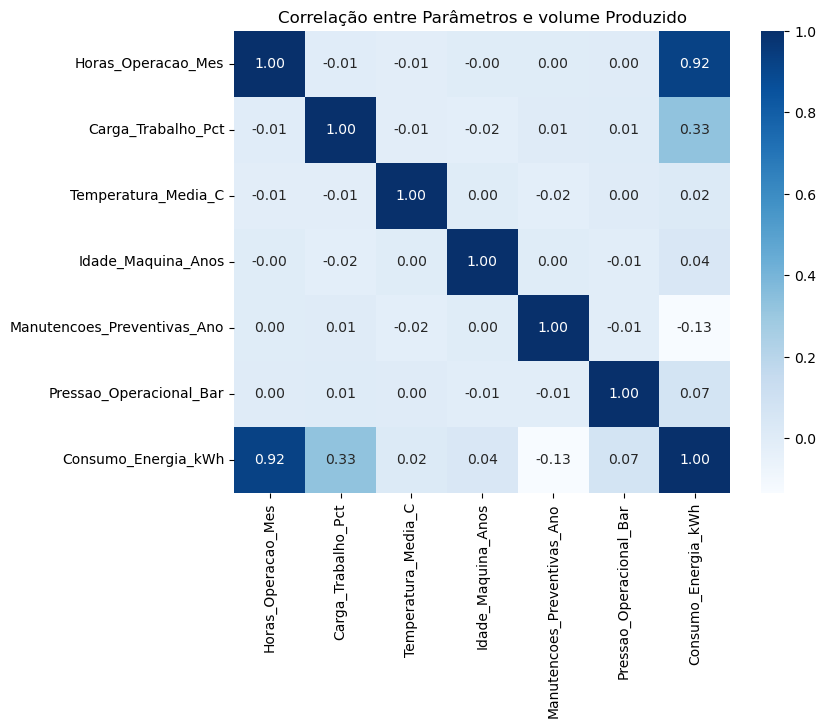

In [17]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlação entre Parâmetros e volume Produzido')
plt.show()

In [20]:
x = df[['Horas_Operacao_Mes', 'Carga_Trabalho_Pct', 'Temperatura_Media_C', 'Idade_Maquina_Anos', 'Manutencoes_Preventivas_Ano', 'Pressao_Operacional_Bar']]
y = df['Consumo_Energia_kWh']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)

In [21]:
modelo_regressao_linear = LinearRegression()
modelo_arvore_regressora = RandomForestRegressor(random_state=42)

In [22]:
modelo_regressao_linear.fit(x_treino, y_treino)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
modelo_arvore_regressora.fit(x_treino, y_treino)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [24]:
previsao_regressao_linear = modelo_regressao_linear.predict(x_teste)
previsao_arvore_regressora = modelo_arvore_regressora.predict(x_teste)

In [25]:
print(f'Regressão Linear: {metrics.r2_score(y_teste, previsao_regressao_linear):.2%}')

Regressão Linear: 98.57%


In [26]:
print(f'Random Forest: {metrics.r2_score(y_teste, previsao_arvore_regressora):.2%}')

Random Forest: 98.12%
